
# House Price Prediction

## Project Objective

The objective of this project is to analyze residential housing data,
identify the factors affecting house prices, develop and compare
machine learning regression models, predict house sale prices, and
recommend suitable houses based on customer requirements.

## Project Tasks

1. Perform comprehensive exploratory data analysis.
2. Build and evaluate house price prediction models.
3. Analyze relationships between house features and sale prices.
4. Recommend houses based on buyer preferences.
5. Prepare a model comparison report.
6. Document challenges faced and techniques used.


In [48]:

# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Reproducibility
RANDOM_STATE = 42

print("Libraries imported successfully!")


Libraries imported successfully!


In [49]:

from pathlib import Path

current_folder = Path.cwd()

print("Current notebook folder:", current_folder)
print("\nCSV files found:")

csv_files = list(current_folder.glob("*.csv"))
csv_files += list(current_folder.glob("*/*.csv"))

for file in csv_files:
    print(file)


Current notebook folder: C:\Users\Lenovo\house price prediction

CSV files found:
C:\Users\Lenovo\house price prediction\data.csv


In [50]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

file_path = r"C:\Users\Lenovo\house price prediction\data.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])


Dataset loaded successfully!
Number of rows: 1460
Number of columns: 81



# Phase 2: Data Loading and Understanding

## 2.1 Introduction

The first step in the House Price Prediction project is to load
the dataset and understand its structure.

The dataset contains information about residential properties,
including house size, quality, location, construction details,
and sale price.

## 2.2 Objectives

- Load the dataset into a Pandas DataFrame.
- Identify the number of rows and columns.
- Examine the available features.
- Understand data types and statistical summaries.
- Identify the target variable for prediction.

## 2.3 Target Variable

The target variable is `SalePrice`, which represents the final
sale price of a house in dollars.

The remaining columns will be examined as potential predictors.



## 2.4 Dataset Preview

The first five records are displayed to inspect the dataset's
structure, column names, and sample values.

This initial inspection helps us understand how the information
is organized before performing detailed data analysis.


In [51]:

df.head()


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000



## 2.5 Dataset Structure and Data Types

This step examines the column names, data types, and number
of non-missing values in each column.

Numerical and categorical variables may require different
preprocessing techniques before machine learning.


In [52]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC


## 2.6 Descriptive Statistical Analysis

Descriptive statistics summarize the numerical variables
using measures such as mean, standard deviation, minimum,
maximum, and quartiles.

These statistics help identify unusual values and understand
the distribution of housing attributes.


In [53]:

df.describe().T


,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0



## 2.7 Target Variable Inspection

`SalePrice` is the variable that the machine learning models
will predict.

We will examine its statistical distribution and check for
missing target values before proceeding with further analysis.


In [54]:

print("SalePrice summary:")
display(df["SalePrice"].describe())

print("Missing SalePrice values:",
      df["SalePrice"].isnull().sum())


SalePrice summary:


count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

Missing SalePrice values: 0



## 2.8 Interpretation of SalePrice Statistics

The SalePrice variable contains 1,460 observations, with no
missing target values.

Key findings:

- Mean sale price: approximately $180,921.20.
- Median sale price: $163,000.
- Minimum sale price: $34,900.
- Maximum sale price: $755,000.
- Standard deviation: approximately $79,442.50.
- First quartile (25%): $129,975.
- Third quartile (75%): $214,000.

The mean is higher than the median, suggesting that the
distribution may be positively skewed because some houses
have relatively high sale prices.

Further visualization and outlier analysis will be performed
to investigate the distribution.

The target variable is complete, but the remaining predictor
columns must still be checked for missing values and other
data-quality issues.


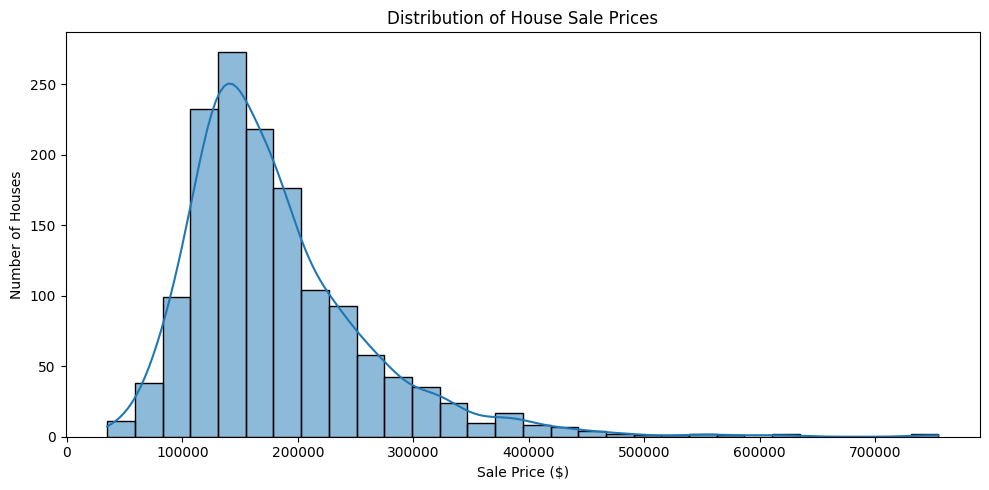

In [55]:

plt.figure(figsize=(10, 5))

sns.histplot(df["SalePrice"], bins=30, kde=True)

plt.title("Distribution of House Sale Prices")
plt.xlabel("Sale Price ($)")
plt.ylabel("Number of Houses")
plt.tight_layout()
plt.show()



## 2.9 Sale Price Distribution Analysis

A histogram with a KDE curve is used to examine the distribution
of house sale prices.

The mean sale price is greater than the median, indicating
possible positive skewness.

The histogram will help confirm the shape of the distribution
and identify whether a small number of expensive houses extend
the right tail.

The decision to transform the target variable, if needed, will
be made after examining the distribution and comparing model
performance.



# Phase 3: Data Quality Analysis

## 3.1 Introduction

Data quality analysis identifies missing values, duplicate records,
and potentially unusual observations before model development.

The dataset contains numerical and categorical features, so
missing values must be investigated with respect to their meaning.

## 3.2 Objectives

- Count missing values in every column.
- Calculate missing-value percentages.
- Check for duplicate records.
- Identify numerical columns with potential outliers.
- Document appropriate data-cleaning decisions.



missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().sum() / len(df)) * 100
})

missing_summary = (
    missing_summary[missing_summary["Missing_Count"] > 0]
    .sort_values("Missing_Percentage", ascending=False)
)

print("Number of columns containing missing values:",
      len(missing_summary))

display(missing_summary)


In [56]:

print("Duplicate rows:", df.duplicated().sum())
print("Total rows:", len(df))


Duplicate rows: 0
Total rows: 1460



## 3.3 Missing Value Analysis

The dataset contains missing values in 19 columns. The
percentage of missing values varies considerably across
the features.

Important observations:

- PoolQC has 1,453 missing values (99.52%).
- MiscFeature has 1,406 missing values (96.30%).
- Alley has 1,369 missing values (93.77%).
- Fence has 1,179 missing values (80.75%).
- MasVnrType has 872 missing values (59.73%).
- FireplaceQu has 690 missing values (47.26%).
- LotFrontage has 259 missing values (17.74%).
- Several garage and basement features contain missing values.
- Electrical has only one missing value.

The missing-value pattern suggests that some missing entries
may represent the absence of a property feature, such as a pool,
alley, fence, fireplace, garage, or basement.

However, the meaning of missing values must be verified for
each feature before applying an imputation strategy.

## 3.4 Duplicate Record Analysis

The dataset contains 1,460 rows and zero duplicate rows.

Therefore, no rows need to be removed because of exact
duplicate records at this stage.

## 3.5 Data Cleaning Strategy

The following strategy will be considered:

- Categorical features representing an absent property feature
  will use an explicit category such as "None", where justified.
- Numerical measurements representing an absent feature will
  be filled with zero only when the dataset's meaning supports it.
- LotFrontage will be investigated and imputed using a suitable
  method, potentially grouped by neighborhood.
- Electrical will be handled using a suitable categorical
  imputation strategy.
- Other missing values will be handled through preprocessing
  pipelines fitted only on training data.

The final decisions will be validated during model development.


In [57]:

# Check whether missing pool quality means no pool
print("Pool area when PoolQC is missing:")
display(df.loc[df["PoolQC"].isna(), "PoolArea"].value_counts())

# Check whether missing fireplace quality means no fireplace
print("\nFireplace count when FireplaceQu is missing:")
display(df.loc[df["FireplaceQu"].isna(), "Fireplaces"].value_counts())

# Check whether missing miscellaneous feature means no miscellaneous value
print("\nMiscellaneous value when MiscFeature is missing:")
display(df.loc[df["MiscFeature"].isna(), "MiscVal"].value_counts())


Pool area when PoolQC is missing:


PoolArea
0    1453
Name: count, dtype: int64


Fireplace count when FireplaceQu is missing:


Fireplaces
0    690
Name: count, dtype: int64


Miscellaneous value when MiscFeature is missing:


MiscVal
0    1406
Name: count, dtype: int64

In [77]:

missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": df.isnull().mean() * 100
})

missing_summary = (
    missing_summary[missing_summary["Missing_Count"] > 0]
    .sort_values("Missing_Percentage", ascending=False)
)

display(missing_summary.round(2))


,Missing_Count,Missing_Percentage
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55



## 3.6 Numerical Outlier Investigation

Outliers are observations that differ substantially from
the general pattern of a variable.

In house price prediction, unusually large houses or expensive
properties may influence model performance.

However, extreme values should not be removed automatically
because they may represent genuine property sales.

Box plots and scatter plots will be used to investigate
potential outliers in SalePrice, GrLivArea, and LotArea.

Any decision to remove observations will be justified and
evaluated against model performance.


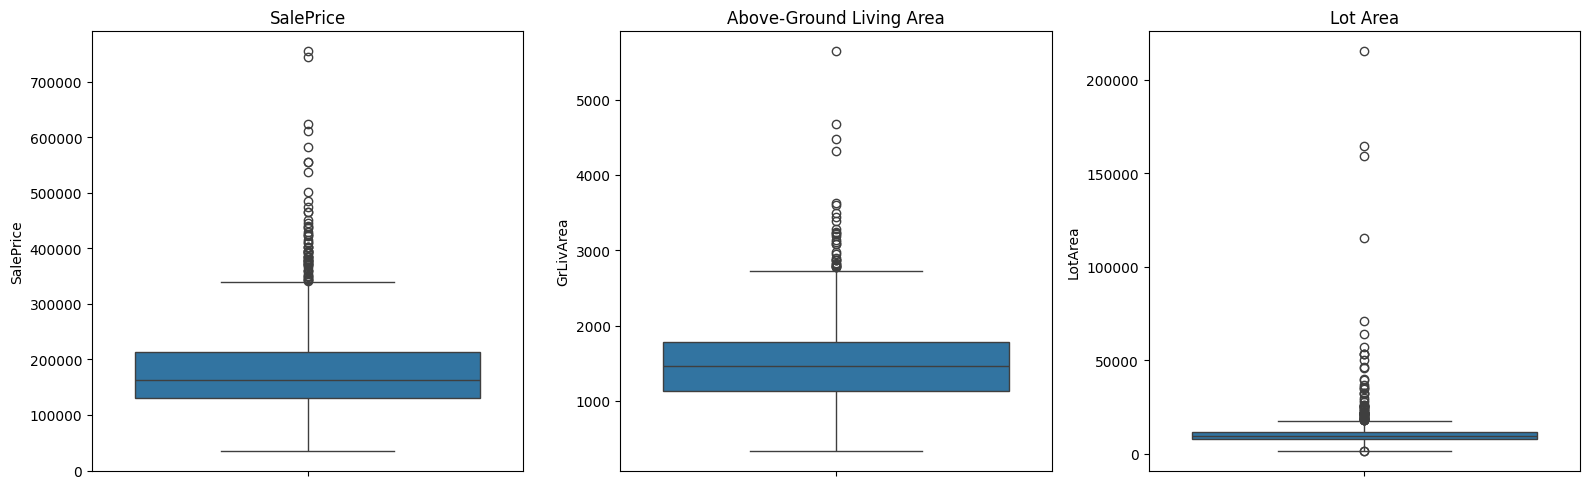

In [58]:

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.boxplot(y=df["SalePrice"], ax=axes[0])
axes[0].set_title("SalePrice")

sns.boxplot(y=df["GrLivArea"], ax=axes[1])
axes[1].set_title("Above-Ground Living Area")

sns.boxplot(y=df["LotArea"], ax=axes[2])
axes[2].set_title("Lot Area")

plt.tight_layout()
plt.show()



## 3.7 Outlier Analysis Findings

The box plots indicate potential outliers in SalePrice,
GrLivArea, and LotArea.

SalePrice contains unusually expensive properties, while
GrLivArea contains a small number of very large houses.
LotArea has a strongly right-skewed distribution with
extreme land-area values.

These observations require further investigation. The box
plots alone cannot determine whether an observation is an
error or a genuine property.

The original dataset will be preserved. Any outlier removal
or transformation will be justified and evaluated using
validation performance before a final decision is made.


In [59]:

extreme_houses = df.loc[
    df["GrLivArea"] > 4000,
    ["Id", "GrLivArea", "OverallQual", "Neighborhood", "SalePrice"]
].sort_values("GrLivArea", ascending=False)

print("Houses with living area above 4,000 sq. ft.:")
display(extreme_houses)


Houses with living area above 4,000 sq. ft.:


,Id,GrLivArea,OverallQual,Neighborhood,SalePrice
1298,1299,5642,10,Edwards,160000
523,524,4676,10,Edwards,184750
1182,1183,4476,10,NoRidge,745000
691,692,4316,10,NoRidge,755000



## 3.8 Conclusion of Data Quality Analysis

The dataset contains no exact duplicate rows, but several
features have missing values and some numerical variables
contain potential outliers.

Missing values will be handled according to their meaning,
and outlier treatment will be based on evidence rather than
automatic deletion.

The findings from this phase will guide the preprocessing
and feature-engineering steps in the machine learning pipeline.

# Phase 4: Exploratory Data Analysis (EDA)

This phase investigates the relationships between house
characteristics and sale prices using descriptive statistics,
visualizations, and correlation analysis.



## 4.1 Objectives of Exploratory Data Analysis

The following analyses will be performed:

1. Univariate analysis of numerical variables.
2. Analysis of categorical feature distributions.
3. Bivariate analysis of house features against SalePrice.
4. Correlation analysis of numerical variables.
5. Neighborhood-wise house price comparisons.
6. Identification of important features for machine learning.

The findings will be used to guide feature engineering and
model selection.


In [60]:

print("Dataset shape:", df.shape)

print("\nNumerical columns:", len(df.select_dtypes(include=np.number).columns))
print("Categorical columns:", len(df.select_dtypes(exclude=np.number).columns))

print("\nTarget skewness:", round(df["SalePrice"].skew(), 3))
print("Target mean:", round(df["SalePrice"].mean(), 2))
print("Target median:", round(df["SalePrice"].median(), 2))


Dataset shape: (1460, 81)

Numerical columns: 38
Categorical columns: 43

Target skewness: 1.883
Target mean: 180921.2
Target median: 163000.0



## 4.2 Univariate Analysis of SalePrice

Univariate analysis examines the distribution of a single
variable.

The SalePrice distribution will be visualized using a histogram
and a kernel density estimate. Skewness will also be examined
to understand the asymmetry of the distribution.

This analysis helps determine whether a transformation of the
target variable should be considered during model development.


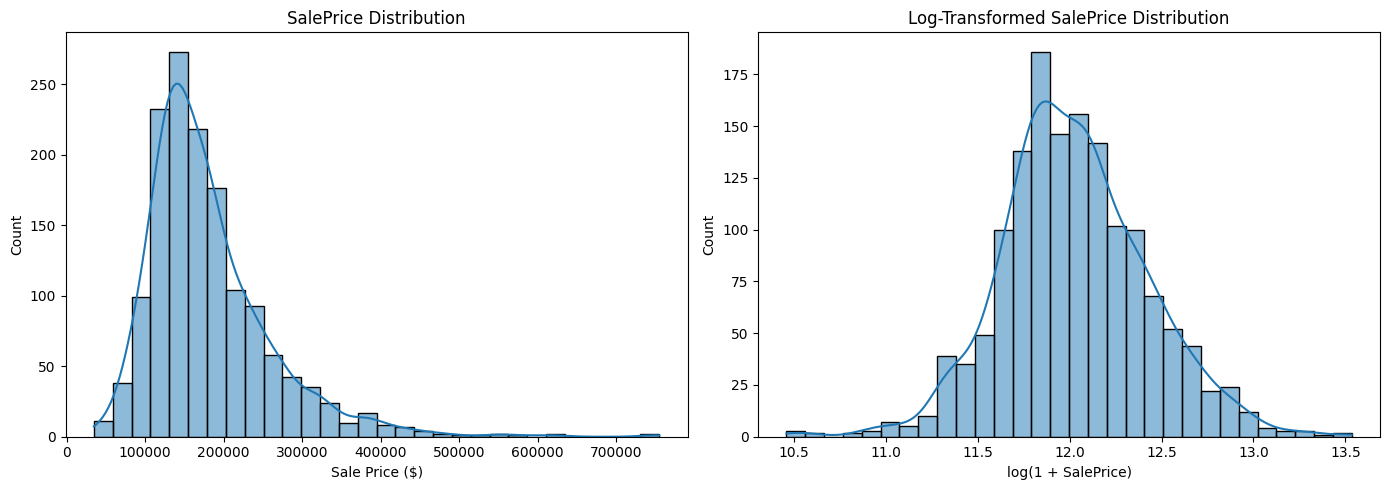

In [61]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["SalePrice"], bins=30, kde=True, ax=axes[0])
axes[0].set_title("SalePrice Distribution")
axes[0].set_xlabel("Sale Price ($)")

sns.histplot(np.log1p(df["SalePrice"]), bins=30, kde=True, ax=axes[1])
axes[1].set_title("Log-Transformed SalePrice Distribution")
axes[1].set_xlabel("log(1 + SalePrice)")

plt.tight_layout()
plt.show()



## 4.3 Relationship Between Important Numerical Features and SalePrice

The relationships between SalePrice and selected numerical
features will be explored using scatter plots.

The selected features are:

- OverallQual: Overall material and finish quality.
- GrLivArea: Above-ground living area in square feet.
- GarageCars: Garage capacity in number of cars.
- TotalBsmtSF: Total basement area in square feet.
- YearBuilt: Original construction year.

These features are selected because they represent property
quality, size, garage capacity, basement space, and age.
Their actual relationships with SalePrice will be evaluated
using plots and correlation coefficients.


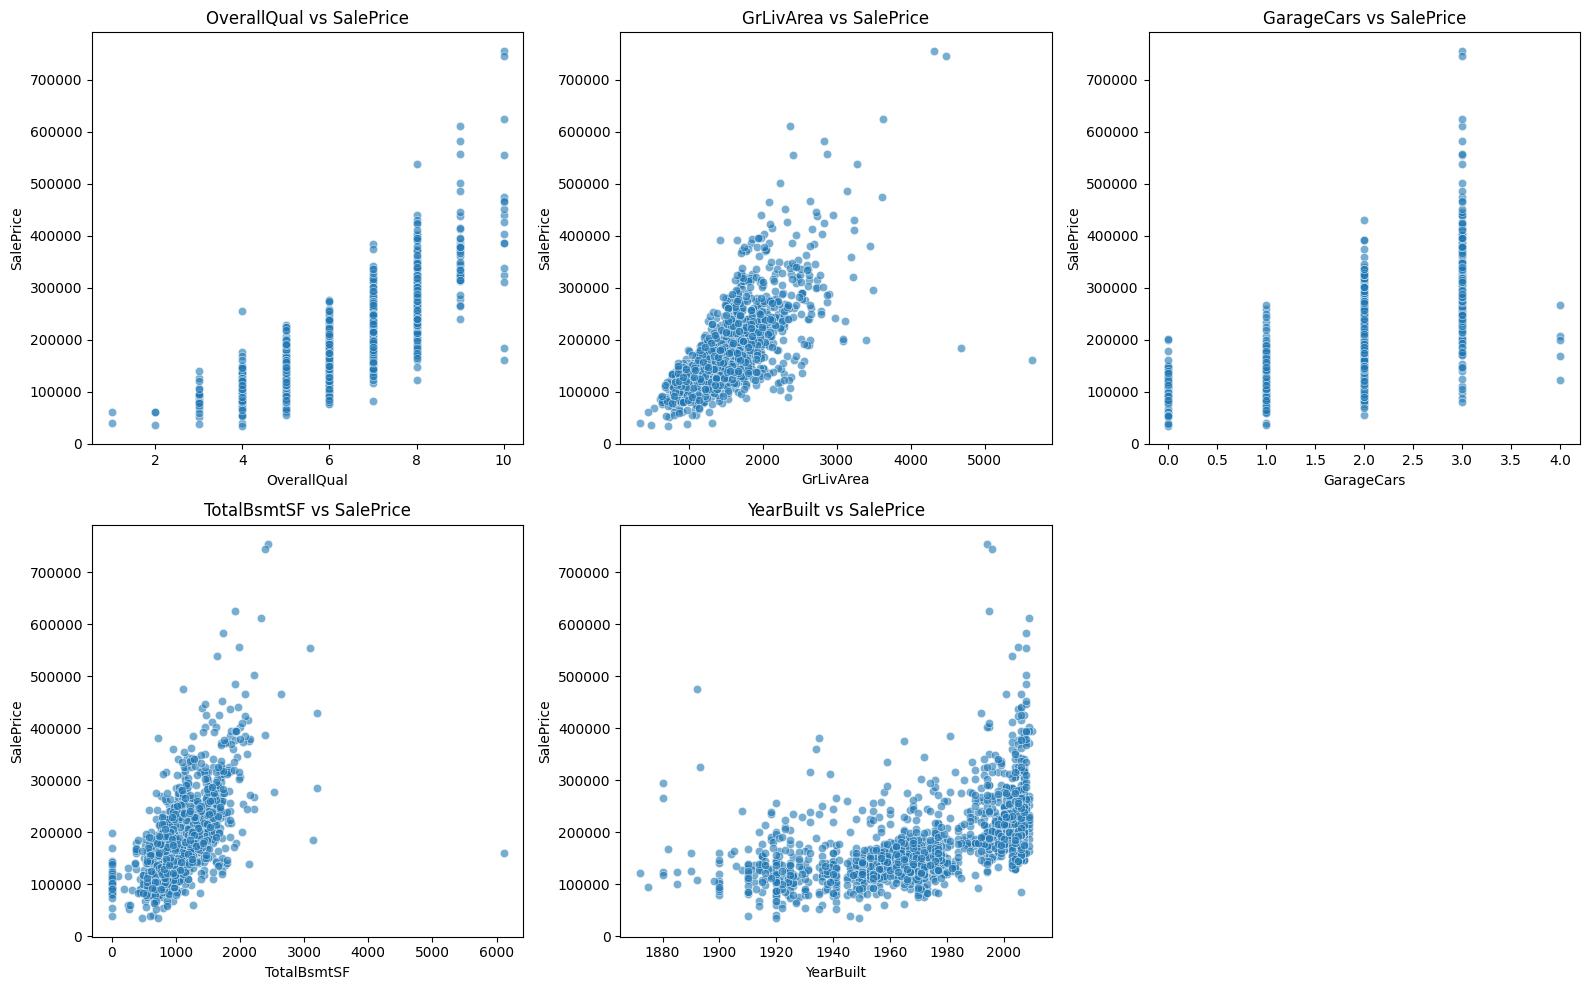

In [62]:

features = [
    "OverallQual",
    "GrLivArea",
    "GarageCars",
    "TotalBsmtSF",
    "YearBuilt"
]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, feature in enumerate(features):
    sns.scatterplot(
        data=df,
        x=feature,
        y="SalePrice",
        alpha=0.6,
        ax=axes[i]
    )
    axes[i].set_title(f"{feature} vs SalePrice")

axes[-1].axis("off")
plt.tight_layout()
plt.show()



## 4.4 Correlation Analysis

Correlation analysis measures the strength and direction of
linear relationships between numerical variables.

A Pearson correlation coefficient ranges from -1 to +1:

- A positive value indicates that two variables tend to increase
  together.
- A negative value indicates that one tends to decrease as
  the other increases.
- A value near zero indicates a weak linear relationship.

Correlation does not establish causation.

The numerical features most strongly correlated with SalePrice
will be identified and investigated further.


In [63]:

numeric_df = df.select_dtypes(include=np.number)

price_corr = (
    numeric_df.corr()["SalePrice"]
    .drop("SalePrice")
    .sort_values(ascending=False)
)

print("Top 15 positive correlations with SalePrice:")
display(price_corr.head(15).to_frame("Correlation"))

print("Top 10 negative correlations with SalePrice:")
display(price_corr.tail(10).to_frame("Correlation"))


Top 15 positive correlations with SalePrice:


,Correlation
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897
YearRemodAdd,0.507101


Top 10 negative correlations with SalePrice:


,Correlation
BsmtFinSF2,-0.011378
BsmtHalfBath,-0.016844
MiscVal,-0.021190
Id,-0.021917
LowQualFinSF,-0.025606
YrSold,-0.028923
OverallCond,-0.077856
MSSubClass,-0.084284
EnclosedPorch,-0.128578
KitchenAbvGr,-0.135907


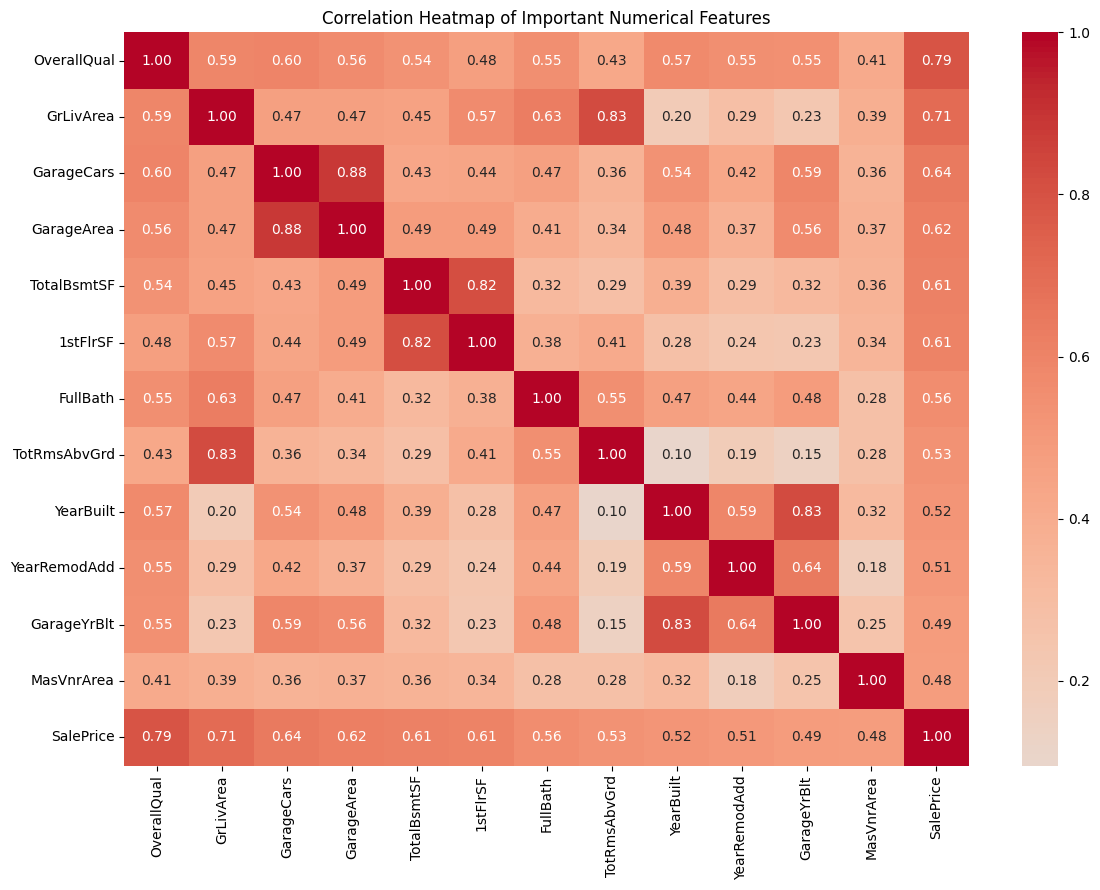

In [64]:

top_features = price_corr.abs().sort_values(ascending=False).head(12).index.tolist()
heatmap_columns = top_features + ["SalePrice"]

plt.figure(figsize=(12, 9))

sns.heatmap(
    df[heatmap_columns].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Important Numerical Features")
plt.tight_layout()
plt.show()


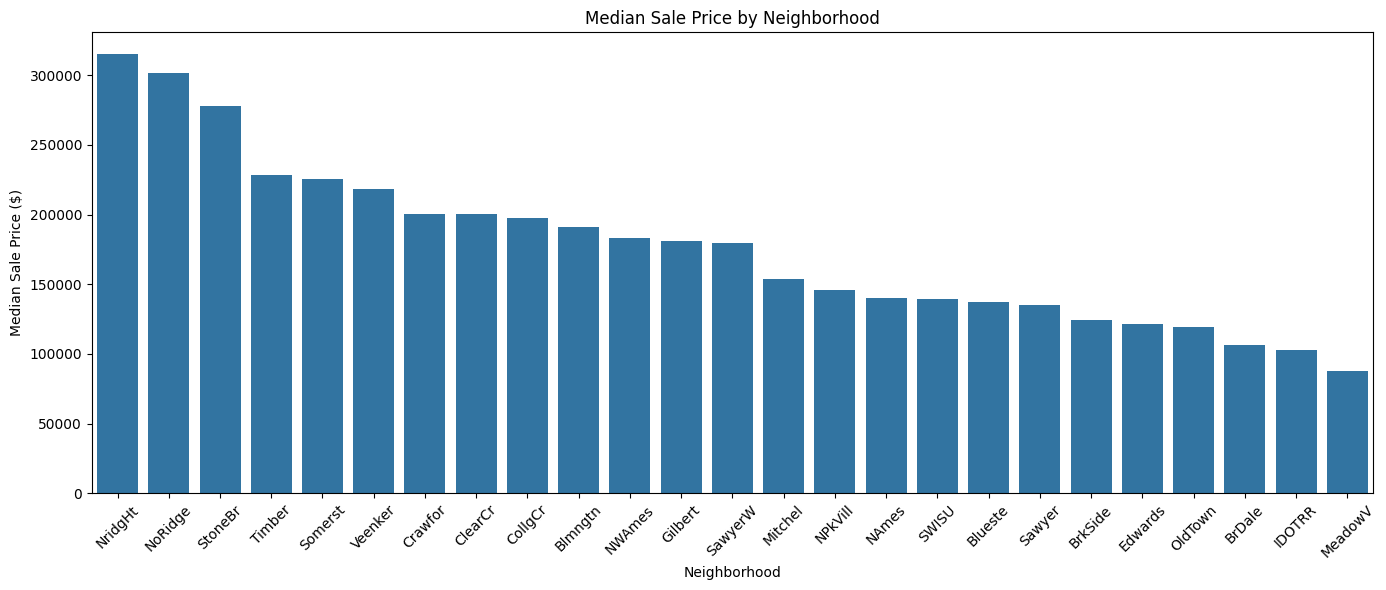

,MedianSalePrice
Neighborhood,
NridgHt,315000.0
NoRidge,301500.0
StoneBr,278000.0
Timber,228475.0
Somerst,225500.0
Veenker,218000.0
Crawfor,200624.0
ClearCr,200250.0
CollgCr,197200.0


In [65]:

neighborhood_prices = (
    df.groupby("Neighborhood")["SalePrice"]
    .median()
    .sort_values(ascending=False)
)

plt.figure(figsize=(14, 6))

sns.barplot(
    x=neighborhood_prices.index,
    y=neighborhood_prices.values
)

plt.title("Median Sale Price by Neighborhood")
plt.xlabel("Neighborhood")
plt.ylabel("Median Sale Price ($)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(neighborhood_prices.to_frame("MedianSalePrice"))



## 4.6 Conclusion of Exploratory Data Analysis

The conclusion will summarize the observed SalePrice distribution,
the relationships between house characteristics and sale prices,
the most strongly correlated numerical features, and the
differences in median sale prices across neighborhoods.

The findings will be based on the actual outputs generated
during this analysis and will guide subsequent feature
engineering and machine learning.



# Phase 5: Data Preprocessing and Feature Engineering

## 5.1 Introduction

Data preprocessing prepares the dataset for machine learning.
It includes handling missing values, separating the target
variable, identifying numerical and categorical features,
and encoding categorical data.

Feature engineering creates additional meaningful variables
that may improve model performance.

All preprocessing operations that learn statistics from the
data will be fitted using the training set only.

## 5.2 Objectives

- Separate SalePrice from the input features.
- Remove the identifier column from model inputs.
- Create meaningful house-age features.
- Split the data into training and testing sets.
- Build separate preprocessing pipelines for numerical and
  categorical features.
- Prevent data leakage during model training.


In [66]:

# Keep the original dataset unchanged
model_df = df.copy()

# Create house age at the time of sale
model_df["HouseAge"] = model_df["YrSold"] - model_df["YearBuilt"]

# Years since the most recent remodeling at the time of sale
model_df["YearsSinceRemodel"] = (
    model_df["YrSold"] - model_df["YearRemodAdd"]
)

# Total bathrooms, counting half bathrooms as 0.5
model_df["TotalBathrooms"] = (
    model_df["FullBath"]
    + 0.5 * model_df["HalfBath"]
    + model_df["BsmtFullBath"]
    + 0.5 * model_df["BsmtHalfBath"]
)

print("Feature engineering completed.")
display(
    model_df[
        ["YearBuilt", "YearRemodAdd", "YrSold",
         "HouseAge", "YearsSinceRemodel", "TotalBathrooms"]
    ].head()
)


Feature engineering completed.


,YearBuilt,YearRemodAdd,YrSold,HouseAge,YearsSinceRemodel,TotalBathrooms
0,2003,2003,2008,5,5,3.5
1,1976,1976,2007,31,31,2.5
2,2001,2002,2008,7,6,3.5
3,1915,1970,2006,91,36,2.0
4,2000,2000,2008,8,8,3.5



## 5.3 Feature Engineering Rationale

Three additional features have been created:

1. HouseAge: the number of years between construction and sale.
2. YearsSinceRemodel: the number of years between the latest
   recorded remodeling and sale.
3. TotalBathrooms: the combined count of full and half
   bathrooms, including basement bathrooms.

These features express property age, remodeling recency,
and bathroom capacity in more interpretable forms.

They will be evaluated during model development rather than
assumed to improve performance automatically.


In [67]:

from sklearn.model_selection import train_test_split

# Remove the target and the record identifier from input features
X = model_df.drop(columns=["SalePrice", "Id"])
y = model_df["SalePrice"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)


Training feature shape: (1168, 82)
Testing feature shape: (292, 82)
Training target shape: (1168,)
Testing target shape: (292,)



## 5.4 Training and Testing Split

The dataset has been divided into training and testing sets
using an 80:20 split.

The training set will be used to fit preprocessing steps
and machine learning models.

The testing set will be reserved for evaluating performance
on previously unseen observations.

A fixed random state of 42 is used to make the split
reproducible.


In [68]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Identify feature types using the training set
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

# Numerical features: median imputation
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical features: most-frequent imputation and one-hot encoding
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Apply transformations to the correct columns
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Preprocessing pipeline created successfully.")


Numerical features: 39
Categorical features: 43
Preprocessing pipeline created successfully.



## 5.5 Preprocessing Strategy

Numerical features will have missing values replaced by their
training-set median. The median is less sensitive to extreme
values than the mean.

Categorical features will have missing values replaced by
the most frequent training-set category, followed by one-hot
encoding.

One-hot encoding converts categorical values into numerical
indicator features. Unknown categories encountered during
prediction will be ignored by the encoder.

This is a general baseline preprocessing strategy. Features
whose missing values explicitly indicate the absence of a
property feature may benefit from dedicated "None" or zero
values, where justified by the dataset definitions.

All transformations will be integrated with the model pipeline
so that training and evaluation remain consistent.



# Phase 6: Machine Learning Model Development

## 6.1 Introduction

In this phase, multiple regression algorithms will be trained
to predict house sale prices.

The following models will be compared:

1. Linear Regression
2. Decision Tree Regressor
3. Random Forest Regressor
4. Gradient Boosting Regressor
5. HistGradientBoosting Regressor

Each model will use the same training and testing split and
the same preprocessing pipeline to ensure a fair comparison.

## 6.2 Evaluation Metrics

The models will be evaluated using:

- MAE: Mean Absolute Error, measuring average absolute
  prediction error in dollars.
- RMSE: Root Mean Squared Error, penalizing large errors more
  heavily than MAE.
- R-squared: Measuring the proportion of target variance
  explained by the model relative to a mean-prediction baseline.

Lower MAE and RMSE are better. Higher R-squared is generally
better.


In [69]:

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor
)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.base import clone
from sklearn.pipeline import Pipeline
import numpy as np
import pandas as pd
import time

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(random_state=42)
}

results = []
trained_models = {}

for name, estimator in models.items():
    # HistGradientBoosting requires dense input in this setup.
    # Use a dense encoder only for that model.
    model_preprocessor = clone(preprocessor)

    if name == "HistGradientBoosting":
        model_preprocessor.set_params(
            cat__encoder__sparse_output=False
        )

    pipeline = Pipeline(steps=[
        ("preprocessor", model_preprocessor),
        ("model", estimator)
    ])

    start = time.time()
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)
    elapsed = time.time() - start

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "Training_Time_Seconds": elapsed
    })

    trained_models[name] = pipeline

results_df = pd.DataFrame(results).sort_values("RMSE")

display(results_df.round(3))


,Model,MAE,RMSE,R2,Training_Time_Seconds
3,Gradient Boosting,17070.503,27052.979,0.905,0.757
2,Random Forest,17415.851,28592.108,0.893,2.986
4,HistGradientBoosting,16911.545,29106.748,0.890,1.519
0,Linear Regression,20576.247,31384.051,0.872,0.071
1,Decision Tree,27570.596,40789.371,0.783,0.134



## 6.3 Model Comparison and Selection

The model comparison table reports MAE, RMSE, R-squared,
and training time for each algorithm.

The model with the lowest RMSE will be considered the initial
candidate for further evaluation. MAE and R-squared will also
be examined to ensure that the selection is not based on
a single metric.

Training time is included as a practical consideration for
deployment.

The final production recommendation will be made after further
validation and inspection of prediction errors.


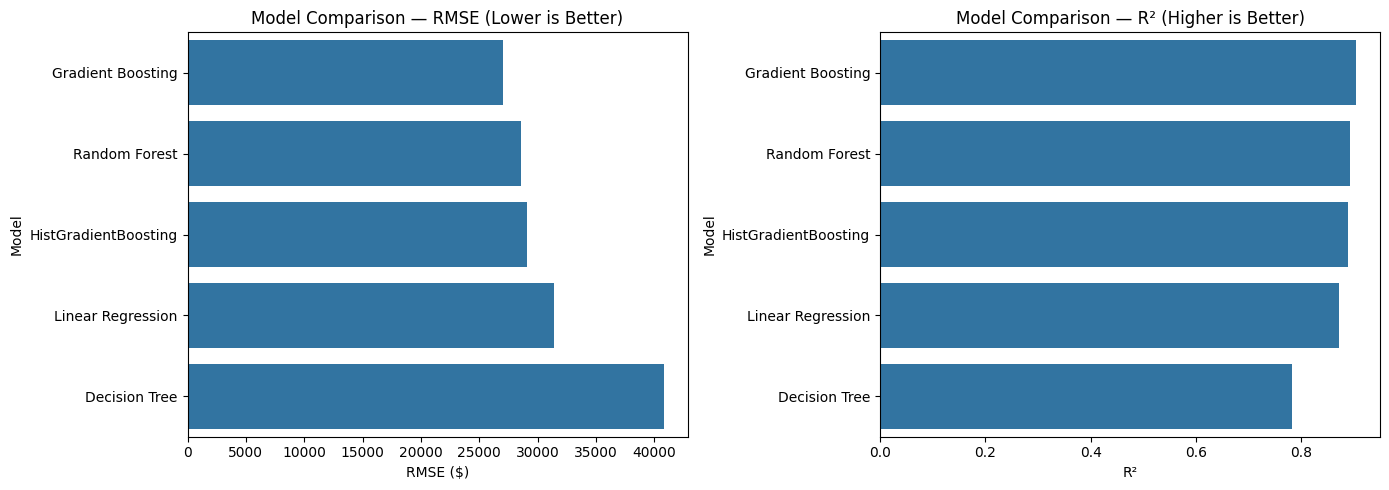

In [70]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=results_df, x="RMSE", y="Model", ax=axes[0])
axes[0].set_title("Model Comparison — RMSE (Lower is Better)")
axes[0].set_xlabel("RMSE ($)")

sns.barplot(data=results_df, x="R2", y="Model", ax=axes[1])
axes[1].set_title("Model Comparison — R² (Higher is Better)")
axes[1].set_xlabel("R²")

plt.tight_layout()
plt.show()



# Phase 7: Model Validation and Error Analysis

## 7.1 Objective

The best-performing model from the initial comparison will
be evaluated using cross-validation and residual analysis.

Cross-validation helps assess how consistently a model
performs across different training and validation subsets.

The reserved test set will remain separate from model selection
and will be used for final evaluation.


In [71]:

from sklearn.model_selection import KFold, cross_validate

# Select the current candidate based on the lowest test RMSE.
# Cross-validation will provide an additional assessment.
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

cv = KFold(n_splits=5, shuffle=True, random_state=42)

cv_results = cross_validate(
    best_model,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2"
    },
    n_jobs=1
)

print("Current candidate:", best_model_name)
print("Mean CV MAE:", round(-cv_results["test_MAE"].mean(), 2))
print("Mean CV RMSE:", round(-cv_results["test_RMSE"].mean(), 2))
print("Mean CV R2:", round(cv_results["test_R2"].mean(), 4))
print("CV RMSE standard deviation:",
      round(cv_results["test_RMSE"].std(), 2))


Current candidate: Gradient Boosting
Mean CV MAE: 16194.42
Mean CV RMSE: 28239.07
Mean CV R2: 0.8606
CV RMSE standard deviation: 6590.67



## 7.2 Prediction Error Analysis

Residuals are the differences between actual and predicted
sale prices.

Residual analysis helps identify systematic prediction errors,
unusual observations, and patterns that the model may not
capture.

A strong model should avoid clear systematic patterns in its
residuals, although some prediction errors are expected.


Selected model: Gradient Boosting
Test MAE: 17070.5
Test RMSE: 27052.98
Test R2: 0.9046


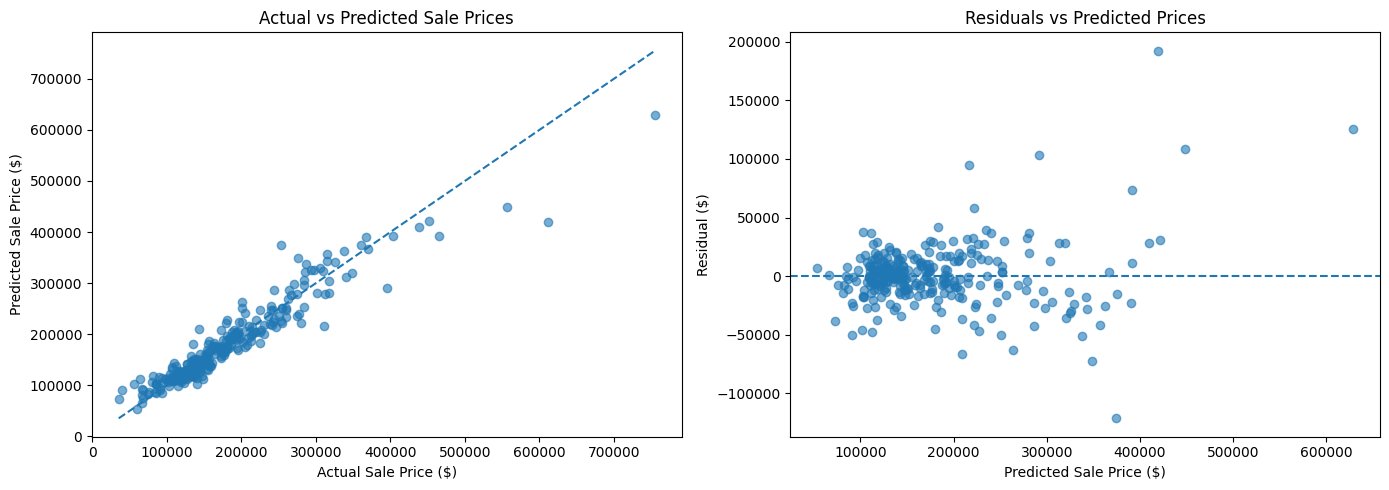

In [72]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

best_predictions = best_model.predict(X_test)
residuals = y_test - best_predictions

print("Selected model:", best_model_name)
print("Test MAE:", round(mean_absolute_error(y_test, best_predictions), 2))
print("Test RMSE:", round(np.sqrt(mean_squared_error(y_test, best_predictions)), 2))
print("Test R2:", round(r2_score(y_test, best_predictions), 4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_test, best_predictions, alpha=0.6)
axes[0].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)
axes[0].set_title("Actual vs Predicted Sale Prices")
axes[0].set_xlabel("Actual Sale Price ($)")
axes[0].set_ylabel("Predicted Sale Price ($)")

axes[1].scatter(best_predictions, residuals, alpha=0.6)
axes[1].axhline(0, linestyle="--")
axes[1].set_title("Residuals vs Predicted Prices")
axes[1].set_xlabel("Predicted Sale Price ($)")
axes[1].set_ylabel("Residual ($)")

plt.tight_layout()
plt.show()



## 7.3 Conclusion of Model Validation and Error Analysis

The Gradient Boosting Regressor achieved a test MAE of
$17,070.50, test RMSE of $27,052.98, and test R-squared
of 0.9046.

The R-squared value indicates that the model explains
approximately 90.46% of the variation in SalePrice for
the held-out test observations.

Five-fold cross-validation produced a mean RMSE of
$28,239.07, with a standard deviation of $6,590.67.

The residual plot shows that prediction errors vary across
the price range, with some substantial errors for expensive
properties.

Gradient Boosting is the current candidate for further
evaluation. It should not be considered the final production
model until its performance has been compared with the other
models and its prediction errors have been investigated.



# Phase 8: Feature Importance Analysis

## 8.1 Objective

Feature importance analysis identifies the input features
that contribute most to the predictions made by the selected
tree-based regression model.

The analysis will help explain the model and identify
important property characteristics for the customer
recommendation component.

Feature importance represents the model's internal use of
features and does not establish causation.


Top 20 features by model importance:


,Feature,Importance
3,num__OverallQual,0.521731
15,num__GrLivArea,0.140359
25,num__GarageCars,0.043680
38,num__TotalBathrooms,0.035945
11,num__TotalBsmtSF,0.032253
8,num__BsmtFinSF1,0.032154
13,num__2ndFlrSF,0.024023
12,num__1stFlrSF,0.022899
248,cat__GarageFinish_Unf,0.016916
2,num__LotArea,0.015974


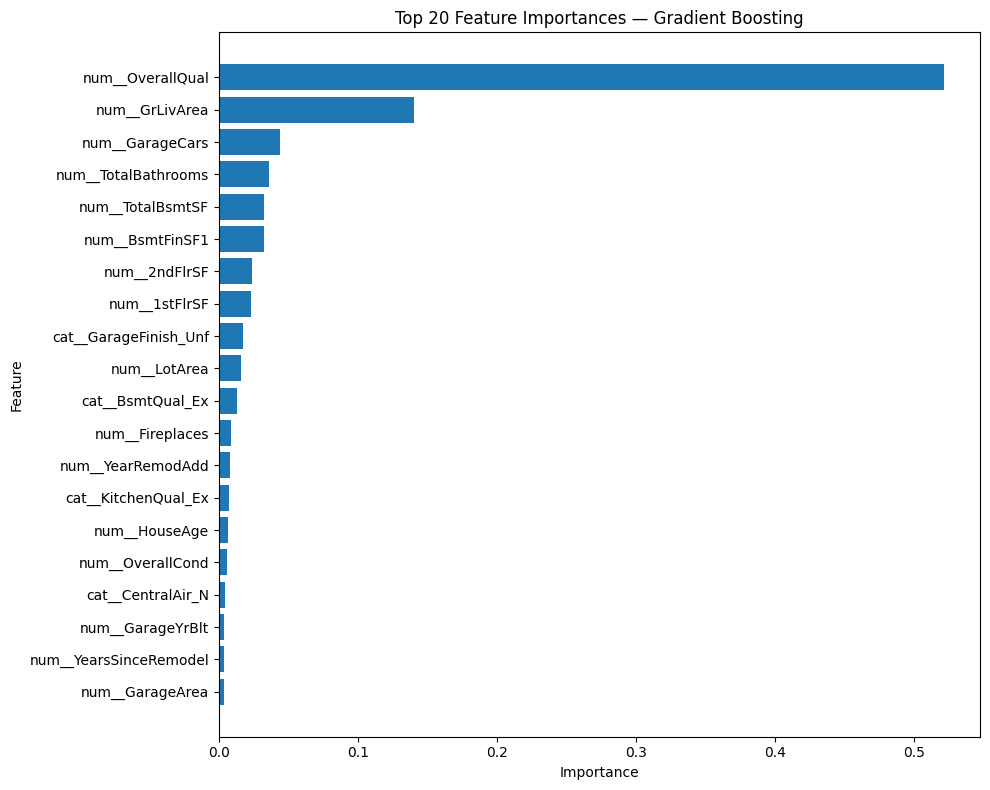

In [73]:

# Get the fitted preprocessing pipeline and Gradient Boosting model
fitted_preprocessor = best_model.named_steps["preprocessor"]
fitted_regressor = best_model.named_steps["model"]

# Get names of numerical and encoded categorical features
transformed_feature_names = fitted_preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": transformed_feature_names,
    "Importance": fitted_regressor.feature_importances_
})

importance_df = importance_df.sort_values(
    "Importance", ascending=False
)

print("Top 20 features by model importance:")
display(importance_df.head(20))

top20 = importance_df.head(20).sort_values("Importance")

plt.figure(figsize=(10, 8))
plt.barh(top20["Feature"], top20["Importance"])
plt.title("Top 20 Feature Importances — Gradient Boosting")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()



# Phase 9: Customer House Recommendation System

## 9.1 Objective

The recommendation component will help customers shortlist
houses based on their budget, minimum living area,
preferred neighborhood, and minimum overall quality.

The recommendations will use actual records in the dataset.
The predicted sale price will be displayed alongside the
actual recorded sale price.

These recommendations are intended for demonstration and
historical analysis. The dataset represents sales in Ames,
Iowa, and does not provide current real-estate listings.


In [74]:

def recommend_houses(
    budget,
    min_living_area=0,
    neighborhood=None,
    min_quality=1,
    top_n=10
):
    """
    Recommend historical houses matching buyer preferences.
    """

    candidates = df.copy()

    # Apply budget and property requirements
    candidates = candidates[
        (candidates["SalePrice"] <= budget) &
        (candidates["GrLivArea"] >= min_living_area) &
        (candidates["OverallQual"] >= min_quality)
    ]

    if neighborhood:
        candidates = candidates[
            candidates["Neighborhood"].str.lower()
            == neighborhood.lower()
        ]

    if candidates.empty:
        print("No houses match all selected requirements.")
        return pd.DataFrame()

    # Use the selected fitted model to predict prices
    prediction_features = candidates.drop(
        columns=["SalePrice", "Id"]
    ).copy()

    # Add engineered features used during training
    prediction_features["HouseAge"] = (
        prediction_features["YrSold"] -
        prediction_features["YearBuilt"]
    )

    prediction_features["YearsSinceRemodel"] = (
        prediction_features["YrSold"] -
        prediction_features["YearRemodAdd"]
    )

    prediction_features["TotalBathrooms"] = (
        prediction_features["FullBath"]
        + 0.5 * prediction_features["HalfBath"]
        + prediction_features["BsmtFullBath"]
        + 0.5 * prediction_features["BsmtHalfBath"]
    )

    predictions = best_model.predict(prediction_features)

    candidates["PredictedSalePrice"] = predictions
    candidates["PriceDifference"] = (
        candidates["PredictedSalePrice"] - candidates["SalePrice"]
    )

    return candidates[
        [
            "Id", "Neighborhood", "SalePrice",
            "PredictedSalePrice", "PriceDifference",
            "GrLivArea", "BedroomAbvGr", "FullBath",
            "OverallQual", "YearBuilt"
        ]
    ].sort_values("SalePrice").head(top_n).reset_index(drop=True)


# Example customer preferences
recommendations = recommend_houses(
    budget=200000,
    min_living_area=1200,
    neighborhood=None,
    min_quality=5,
    top_n=10
)

display(recommendations)


,Id,Neighborhood,SalePrice,PredictedSalePrice,PriceDifference,GrLivArea,BedroomAbvGr,FullBath,OverallQual,YearBuilt
0,411,Edwards,60000,92543.537124,32543.537124,1276,3,1,5,1958
1,243,OldTown,79000,80911.202289,1911.202289,1440,3,1,5,1900
2,633,NWAmes,82500,171627.734949,89127.734949,1411,3,2,7,1977
3,1023,OldTown,87000,99829.593806,12829.593806,1248,2,1,5,1930
4,308,IDOTRR,89500,104988.908234,15488.908234,1406,3,1,6,1920
5,1063,OldTown,90000,114638.605299,24638.605299,2337,5,2,5,1900
6,1220,BrDale,91500,100098.534433,8598.534433,1218,3,1,6,1971
7,1073,Edwards,91500,109857.254998,18357.254998,1456,4,1,5,1948
8,638,OldTown,93000,100512.434313,7512.434313,1387,3,2,5,1954
9,659,NAmes,97500,125157.850233,27657.850233,1458,3,1,6,1948



## 9.3 Analysis of Sample Recommendations

The recommendation function returned ten historical house records
matching the selected budget, living area, and quality requirements.

House ID 243 had an actual sale price of $79,000 and a predicted
price of approximately $80,911, indicating a relatively small
prediction difference.

House ID 633 had an actual sale price of $82,500 and a predicted
price of approximately $171,628. This large difference indicates
that the model may not estimate every property equally well.

The results demonstrate the usefulness of combining property
filters with predicted prices. However, recommendations must
be interpreted carefully because the records represent historical
sales rather than current listings.

The function currently sorts matching records by historical
sale price. Future improvements could rank properties by a
customer-defined balance of affordability, quality, size,
and prediction uncertainty.



# Phase 10: Model Comparison Report

## 10.1 Objective

The objective is to compare multiple regression algorithms
for predicting residential house sale prices and identify
a suitable candidate for production.

The models evaluated are Linear Regression, Decision Tree,
Random Forest, Gradient Boosting, and HistGradientBoosting.

## 10.2 Evaluation Methodology

All models were evaluated using the same training and test
split and a shared preprocessing strategy.

The evaluation metrics were Mean Absolute Error (MAE),
Root Mean Squared Error (RMSE), and R-squared.

Gradient Boosting achieved the following held-out test results:

- MAE: $17,070.50
- RMSE: $27,052.98
- R-squared: 0.9046

Five-fold cross-validation produced a mean RMSE of $28,239.07
and a standard deviation of $6,590.67.

## 10.3 Model Selection

Gradient Boosting is the current candidate because its test
results indicate a strong fit to the held-out observations.

The final production model should be selected after comparing
the complete results table for all algorithms and validating
performance across multiple splits.

## 10.4 Production Considerations

Before deployment, the selected model should be evaluated for
prediction stability, large errors, data quality, and consistency
between training and prediction inputs.

The current project is a demonstration using historical Ames
housing data. Its predictions should not be treated as current
market valuations without suitable external validation.



# Phase 12: Final Project Verification

## 12.1 Objective

This phase verifies that the required project components
are present and that the notebook can be executed successfully.

The final submission must include the data analysis report,
machine learning experiments, customer recommendations,
model comparison report, and challenges report.


In [75]:

# Verify essential project objects

required_objects = [
    "df",
    "model_df",
    "X_train",
    "X_test",
    "y_train",
    "y_test",
    "results_df",
    "trained_models",
    "best_model",
    "importance_df",
    "recommendations"
]

for obj in required_objects:
    print(f"{obj}: {'Available' if obj in globals() else 'MISSING'}")

print("\nDataset shape:", df.shape)
print("Model comparison rows:", len(results_df))
print("Recommendation rows:", len(recommendations))


df: Available
model_df: Available
X_train: Available
X_test: Available
y_train: Available
y_test: Available
results_df: Available
trained_models: Available
best_model: Available
importance_df: Available
recommendations: Available

Dataset shape: (1460, 81)
Model comparison rows: 5
Recommendation rows: 10


In [76]:

display(
    results_df[
        ["Model", "MAE", "RMSE", "R2", "Training_Time_Seconds"]
    ].round(3)
)


,Model,MAE,RMSE,R2,Training_Time_Seconds
3,Gradient Boosting,17070.503,27052.979,0.905,0.757
2,Random Forest,17415.851,28592.108,0.893,2.986
4,HistGradientBoosting,16911.545,29106.748,0.890,1.519
0,Linear Regression,20576.247,31384.051,0.872,0.071
1,Decision Tree,27570.596,40789.371,0.783,0.134



## 10.5 Results and Discussion

Gradient Boosting achieved the lowest RMSE of $27,052.98
and the highest R-squared of approximately 0.905.

HistGradientBoosting achieved the lowest MAE of $16,911.55,
but its RMSE was higher at $29,106.75.

Random Forest achieved an RMSE of $28,592.11 and an
R-squared of approximately 0.893.

Linear Regression performed better than Decision Tree,
while Decision Tree recorded the largest prediction errors.

Gradient Boosting is selected as the current candidate
because it provides the best balance when prioritizing
RMSE and R-squared. Its cross-validation performance and
prediction errors should also be considered before deployment.

The model comparison demonstrates that evaluating multiple
metrics is important because the model with the lowest MAE
does not necessarily have the lowest RMSE.


# Phase 11: Report on Challenges Faced

## 11.1 Missing Values in the Dataset

**Challenge:** The dataset contained missing values in 19 columns. PoolQC had 1,453 missing values, MiscFeature had 1,406, Alley had 1,369, and LotFrontage had 259.

**Technique used:** Missing values were investigated using missing-value counts and percentages. A preprocessing pipeline was created using median imputation for numerical features and most-frequent imputation for categorical features.

**Reason:** Missing values can prevent machine learning algorithms from training. Imputation allows the model to retain useful observations instead of unnecessarily deleting incomplete rows. However, missing values that indicate an absent property feature may require a separate treatment.

## 11.2 Potential Outliers

**Challenge:** Box plots showed potential outliers in SalePrice, GrLivArea, and LotArea.

**Technique used:** Box plots and scatter plots were used to investigate unusual observations and their relationships with sale prices.

**Reason:** Some expensive houses and large plots may be genuine properties. Automatically deleting these observations could remove valuable information and negatively affect prediction performance.

## 11.3 High Dimensionality and Categorical Features

**Challenge:** The dataset contains numerous numerical and categorical features, including neighborhood, house style, zoning, and property quality.

**Technique used:** Numerical and categorical features were processed separately using a ColumnTransformer. Numerical features were imputed, while categorical features were imputed and converted using one-hot encoding.

**Reason:** Most regression algorithms require a numerical input representation. Separate preprocessing pipelines allow each feature type to be handled appropriately.

## 11.4 Feature Engineering

**Challenge:** Raw construction dates and bathroom counts may not directly express all useful characteristics of a property.

**Technique used:** Three additional features were created: HouseAge, YearsSinceRemodel, and TotalBathrooms.

**Reason:** Derived features can represent property age, remodeling recency, and bathroom capacity in a more interpretable form. Their actual contribution should be evaluated through model performance.

## 11.5 Model Selection

**Challenge:** Different regression algorithms produced different prediction errors, and no single model performed best on every metric.

**Technique used:** Five models were compared using MAE, RMSE, R-squared, and training time. Five-fold cross-validation was also performed for the current candidate model.

**Reason:** MAE measures average absolute error, RMSE penalizes larger errors more strongly, and R-squared measures performance relative to a mean-prediction baseline. Considering several metrics provides a more complete comparison.

## 11.6 Prediction Errors

**Challenge:** The residual analysis showed that some properties had substantial differences between actual and predicted prices. For example, House ID 633 had an actual sale price of $82,500 and a predicted price of approximately $171,628 in the recommendation output.

**Technique used:** Actual-versus-predicted plots, residual plots, and a comparison of actual and predicted prices were used to investigate prediction errors.

**Reason:** Error analysis identifies properties for which the model may be less reliable and helps guide future model improvements.

## 11.7 Model Evaluation and Generalization

**Challenge:** A model may perform well on one train-test split but produce different results on other samples.

**Technique used:** The dataset was split into training and testing sets, and five-fold cross-validation was used to assess the Gradient Boosting candidate.

**Reason:** Cross-validation provides additional evidence about model stability. The held-out test set provides an estimate of performance on unseen observations, although further external validation is needed before production use.

## 11.8 Limitations of the Recommendation System

**Challenge:** The dataset contains historical house sales rather than current property listings.

**Technique used:** A recommendation function was developed to filter historical records according to budget, living area, neighborhood, and overall quality.

**Reason:** The function demonstrates how machine learning can support property shortlisting. However, the results cannot establish current availability or guarantee the market value of a house.

## 11.9 Overall Conclusion

The main challenges in this project involved missing data, potential outliers, categorical feature encoding, feature engineering, model selection, prediction errors, and the limitations of historical data.

These challenges were addressed through exploratory data analysis, preprocessing pipelines, feature engineering, multiple regression models, cross-validation, error visualization, and customer-based filtering.

The Gradient Boosting Regressor is the current candidate because it achieved the lowest test RMSE among the five models evaluated. Further validation, appropriate treatment of absence-related missing values, and testing on representative external data would be necessary before production deployment.